In [1]:
from __future__ import annotations
import pandas as pd
import numpy as np
import scanpy as sc
import scanpy.external as sce
import anndata as ad
import warnings
warnings.filterwarnings("ignore")
import hdf5plugin #in case needed for h5ad reading (if previously saved with compression)
import decoupler as dc


etmr1 = ad.io.read_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/snrna_data_leiden.h5ad")



In [2]:
markers = pd.read_csv("/home/sofia/Projects/etmr/defaria/marker_ref.csv")
markers_wide = markers.pivot(columns='source', values='target')


In [3]:
markers = markers_wide.to_dict("list")
markers = {k: [v for v in vals if pd.notna(v)] for k, vals in markers.items()}

In [4]:
valid_values = set(etmr1.var.index)  # convert to set for faster lookup
markers = {k: [v for v in vals if v in valid_values] for k, vals in markers.items()}

In [5]:
etmr1

AnnData object with n_obs × n_vars = 49124 × 18082
    obs: 'orig.ident', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'Sample_ID', 'Tumor_Type', 'leiden_r0.5_n10_pc30', 'leiden_r0.5_n10_pc40', 'leiden_r0.5_n10_pc50', 'leiden_r1.0_n10_pc30', 'leiden_r1.0_n10_pc40', 'leiden_r1.0_n10_pc50', 'leiden_r1.5_n10_pc30', 'leiden_r1.5_n10_pc40', 'leiden_r1.5_n10_pc50', 'leiden_r0.5_n15_pc30', 'leiden_r0.5_n15_pc40', 'leiden_r0.5_n15_pc50', 'leiden_r1.0_n15_pc30', 'leiden_r1.0_n15_pc40', 'leiden_r0.5_n25_pc40', 'leiden_r0.7_n25_pc40', 'leiden_r1.0_n25_pc40', 'leiden_r1.2_n25_pc40', 'leiden_r1.5_n25_pc40', 'leiden_r0.5_n30_pc40', 'leiden_r0.7_n30_pc40', 'leiden_r1.0_n30_pc40', 'leiden_r1.2_n30_pc40', 'leiden_r1.5_n30_pc40', 'leiden_r0.5_n25_pc50', 'leiden_r0.7_n25_pc50', 'leiden_r1.0_n25_pc50', 'leiden_r1.2_n25_pc50', 'leiden_r1.5_n25_pc50', 'leiden_r0.5_n30_pc50', 'leiden_r0.7_n30_pc50', 'leiden_r1.0_n30_pc50', 'leiden_r1.2_n30_pc50', 'leiden_r1.5_n30_pc50'
    var: 'g

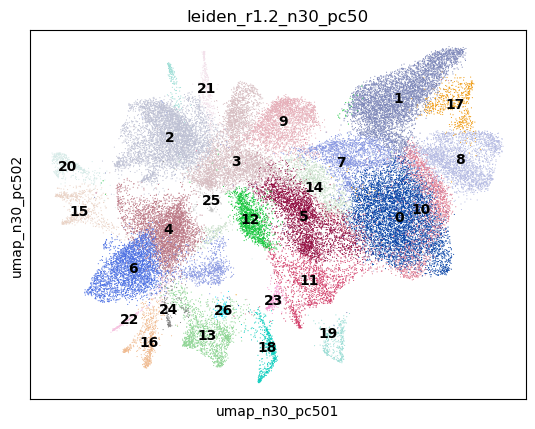

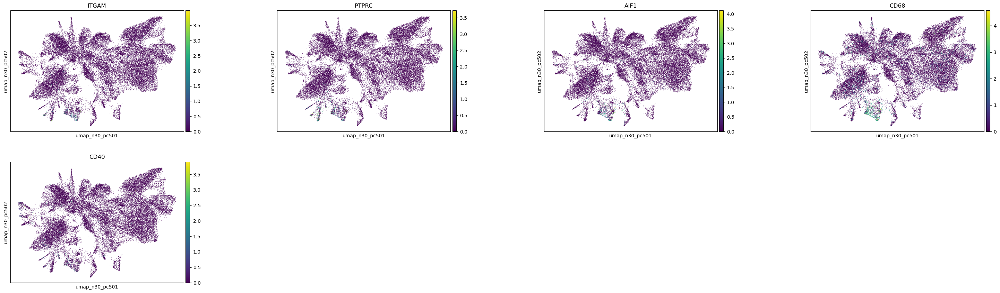

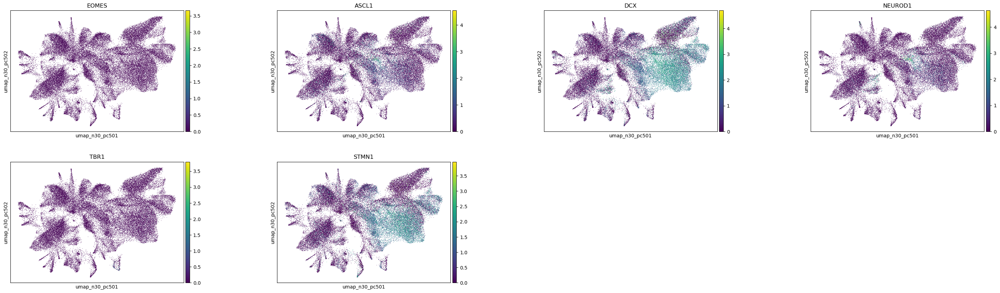

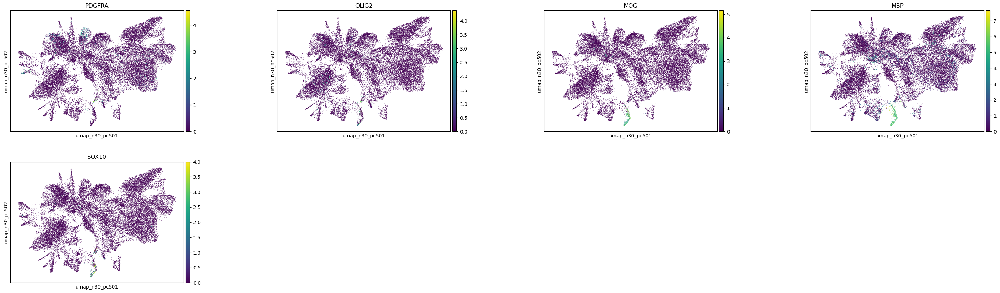

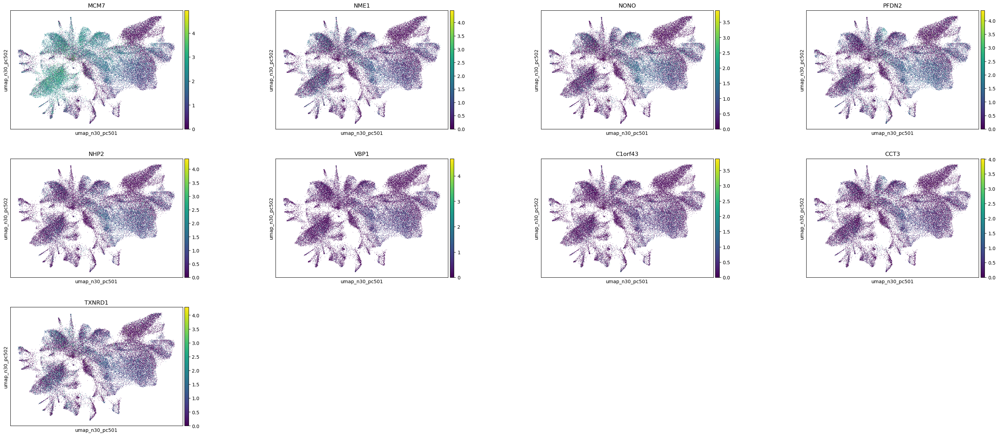

In [9]:
sc.pl.embedding(etmr1, basis="umap_n30_pc50", color=["leiden_r1.2_n30_pc50"], wspace=0.4, legend_loc='on data')
sc.pl.embedding(etmr1, basis="umap_n30_pc50", color=markers["Microglia"], wspace=0.4)
sc.pl.embedding(etmr1, basis="umap_n30_pc50", color=markers["Intprog"], wspace=0.4)
sc.pl.embedding(etmr1, basis="umap_n30_pc50", color=markers["Oligodendrocytes "], wspace=0.4)
sc.pl.embedding(etmr1, basis="umap_n30_pc50", color=markers["Malignant"], wspace=0.4)

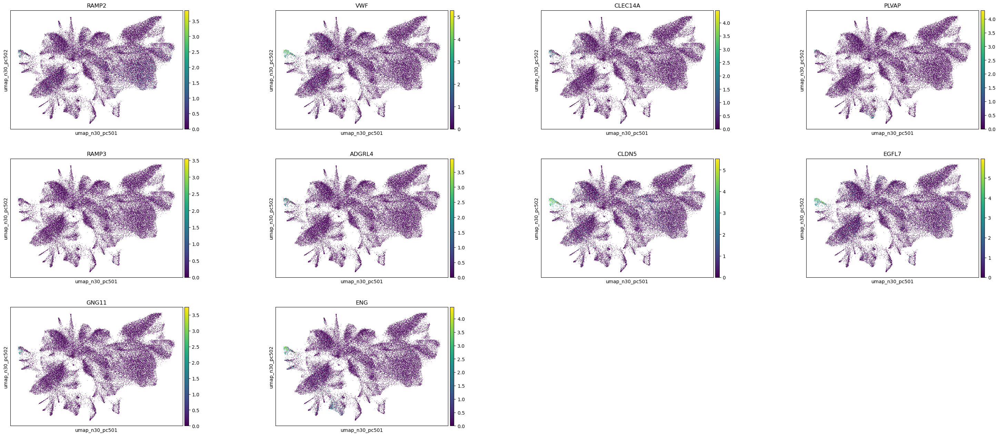

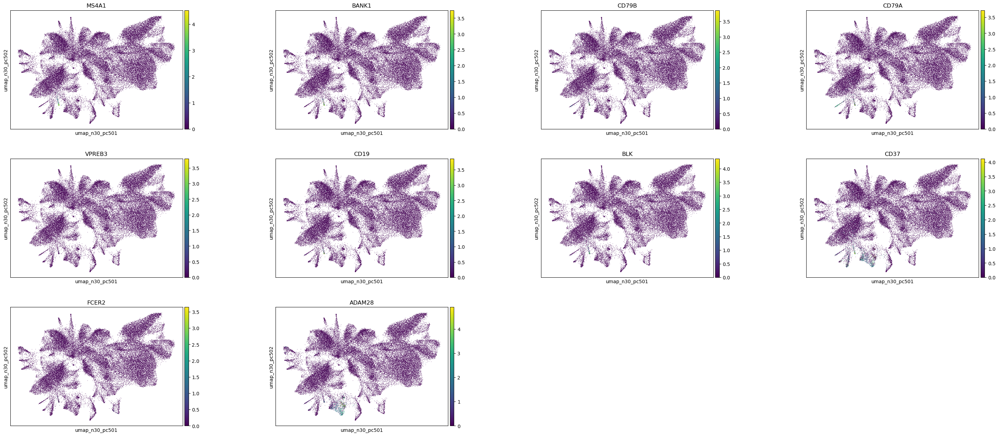

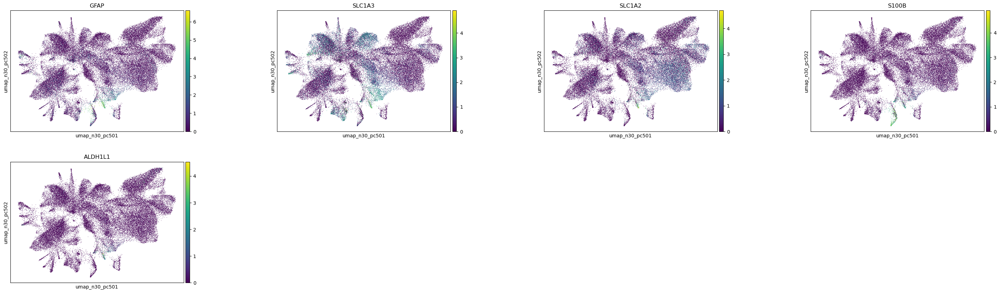

In [10]:
sc.pl.embedding(etmr1, basis="umap_n30_pc50", color=markers["Endothelial"], wspace=0.4)
sc.pl.embedding(etmr1, basis="umap_n30_pc50", color=markers["Bcell"], wspace=0.4)
sc.pl.embedding(etmr1, basis="umap_n30_pc50", color=markers["Astrocytes"], wspace=0.4)

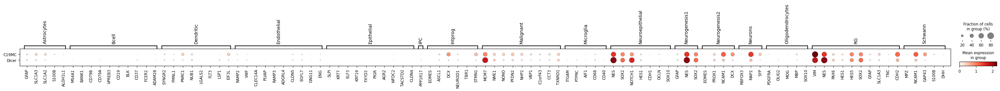

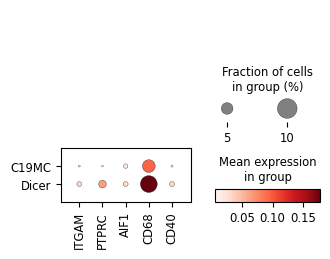

In [11]:

sc.pl.dotplot(etmr1, markers, groupby="Tumor_Type", standard_scale=None)
sc.pl.dotplot(etmr1, markers["Microglia"], groupby="Tumor_Type", standard_scale=None)


In [12]:
#markers = markers.pivot(columns='CellType', values='Marker')
markers = pd.read_excel("/home/sofia/Projects/etmr/defaria/marker_ref.xlsx", sheet_name="cellxgene")
markers

,source,target,alias1,alias2,alias3,alias4,alias5
0,Schwann,ABCA8,NaN,NaN,NaN,NaN,NaN
1,Epithelial,ABCB1,ABC20,CD243,CLCS,ENPAT,GP170
2,Astrocytes,ADCY2,AC2,HBAC2,NaN,NaN,NaN
3,Epithelial,ADGRF5,GPR116,KPG_001,NaN,NaN,NaN
4,Epithelial,ADGRL4,ELTD1,ETL,KPG_003,NaN,NaN
...,...,...,...,...,...,...,...
198,Oligodendrocytes,TMEM144,SLC35G7,NaN,NaN,NaN,NaN
199,Oligodendrocytes,TMTC2,IBDBP1,NaN,NaN,NaN,NaN
200,Oligodendrocytes,TTLL7,NaN,NaN,NaN,NaN,NaN
201,RG,TTYH1,NaN,NaN,NaN,NaN,NaN


In [13]:


panglao = dc.op.resource("PanglaoDB", organism="human")
panglao
# dc.mt.ulm(data=etmr1, net=go, tmin=3)
# etmr1.obsm["score_ulm"]

,genesymbol,canonical_marker,cell_type,germ_layer,human,human_sensitivity,human_specificity,mouse,mouse_sensitivity,mouse_specificity,ncbi_tax_id,organ,ubiquitiousness
,,,,,,,,,,,,,
0,A1CF,False,Hepatocytes,Endoderm,True,0.189189,0.004437,True,0.175000,0.000257,9606,Liver,0.002
1,A2APA5,False,Germ cells,Mesoderm,False,0.000000,0.000000,True,0.432927,0.000000,10090,Reproductive,0.004
2,A2M,True,Bergmann glia,Ectoderm,True,0.000000,0.062343,True,0.333333,0.001604,9606,Brain,0.012
3,A3FIN4,False,Mast cells,Mesoderm,False,0.000000,0.000000,True,0.184211,0.000708,10090,Immune system,0.001
4,A4GALT,True,Mast cells,Mesoderm,True,0.000000,0.014133,True,0.000000,0.003023,9606,Immune system,0.005
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8206,ZNF521,False,Adipocyte progenitor cells,Mesoderm,True,0.000000,0.010338,False,0.000000,0.000000,9606,Connective tissue,0.002
8207,ZNRF4,False,Germ cells,Mesoderm,True,0.284360,0.000000,True,0.000000,0.000000,9606,Reproductive,0.010
8208,ZPBP2,True,Germ cells,Mesoderm,True,0.436019,0.000000,True,0.000000,0.000000,9606,Reproductive,0.008


In [14]:
# Filter by canonical_marker and human
panglao = panglao[
     panglao["human"].astype(bool)
     & panglao["canonical_marker"].astype(bool)
     & (panglao["human_sensitivity"].astype(float) > 0.5)
 ]

# Remove duplicated entries
panglao = panglao[~panglao.duplicated(["cell_type", "genesymbol"])]
 # Format
panglao = panglao.rename(columns={"cell_type": "source", "genesymbol": "target"})
panglao = panglao[["source", "target"]]
panglao

,source,target
,,
18,Pulmonary alveolar type II cells,ABCA3
90,Enterocytes,ACSL5
105,Smooth muscle cells,ACTA2
113,Smooth muscle cells,ACTG2
114,Myoepithelial cells,ACTG2
...,...,...
8092,Endothelial cells,VWF
8101,Luminal epithelial cells,WFDC2
8102,Ductal cells,WFDC2


In [28]:
dc.mt.ulm(data=etmr1, net=panglao, tmin=3)
score_pang = dc.pp.get_obsm(adata=etmr1, key="score_ulm")

In [29]:
braincells = ["Astrocytes",
"Neurons",
"Ependymal cells",
"Oligodendrocyte progenitor cells",
"Oligodendrocytes",
"Endothelial cells",
"Pericytes",
"Fibroblasts",
"Macrophages",
"Monocytes",
"Dendritic cells",
"Plasmacytoid dendritic cells",
"T cells",
"B cells",
"B cells naive",
"Plasma cells",
"NK cells",
"Gamma delta T cells",
"Neutrophils",
"Mast cells",
"Platelets"]

score_pang = score_pang[:,braincells]

In [30]:
score_pang

View of AnnData object with n_obs × n_vars = 49124 × 21
    obs: 'orig.ident', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'Sample_ID', 'Tumor_Type', 'leiden_r0.5_n10_pc30', 'leiden_r0.5_n10_pc40', 'leiden_r0.5_n10_pc50', 'leiden_r1.0_n10_pc30', 'leiden_r1.0_n10_pc40', 'leiden_r1.0_n10_pc50', 'leiden_r1.5_n10_pc30', 'leiden_r1.5_n10_pc40', 'leiden_r1.5_n10_pc50', 'leiden_r0.5_n15_pc30', 'leiden_r0.5_n15_pc40', 'leiden_r0.5_n15_pc50', 'leiden_r1.0_n15_pc30', 'leiden_r1.0_n15_pc40', 'leiden_r0.5_n25_pc40', 'leiden_r0.7_n25_pc40', 'leiden_r1.0_n25_pc40', 'leiden_r1.2_n25_pc40', 'leiden_r1.5_n25_pc40', 'leiden_r0.5_n30_pc40', 'leiden_r0.7_n30_pc40', 'leiden_r1.0_n30_pc40', 'leiden_r1.2_n30_pc40', 'leiden_r1.5_n30_pc40', 'leiden_r0.5_n25_pc50', 'leiden_r0.7_n25_pc50', 'leiden_r1.0_n25_pc50', 'leiden_r1.2_n25_pc50', 'leiden_r1.5_n25_pc50', 'leiden_r0.5_n30_pc50', 'leiden_r0.7_n30_pc50', 'leiden_r1.0_n30_pc50', 'leiden_r1.2_n30_pc50', 'leiden_r1.5_n30_pc50'
    un

In [ ]:

score_pang.obsm["score_ulm"] = score_pang.obsm["score_ulm"].loc[:,braincells]
score_pang.obsm["padj_ulm"] = score_pang.obsm["padj_ulm"].loc[:,braincells]

In [32]:
score_pang.obsm["score_ulm"].max()

#sc.pl.embedding(score_pang, basis="X_umap_unintegrated", color=["Malignant"], wspace=0.4, cmap="RdBu_r", vcenter=0)

Astrocytes                          22.479409
Neurons                             14.052896
Ependymal cells                      6.139585
Oligodendrocyte progenitor cells    17.392473
Oligodendrocytes                    28.812645
Endothelial cells                   23.631143
Pericytes                           17.484942
Fibroblasts                         33.038364
Macrophages                         17.618197
Monocytes                           11.596702
Dendritic cells                     11.944392
Plasmacytoid dendritic cells        17.085292
T cells                             16.140370
B cells                             15.079515
B cells naive                       17.615183
Plasma cells                        28.819525
NK cells                            18.217279
Gamma delta T cells                 19.964117
Neutrophils                          9.200960
Mast cells                          12.845243
Platelets                            7.301422
dtype: float64

In [33]:
score_pang.obsm["score_ulm"].min()

Astrocytes                         -2.272714
Neurons                            -1.672972
Ependymal cells                    -1.519457
Oligodendrocyte progenitor cells   -1.483502
Oligodendrocytes                   -2.462599
Endothelial cells                  -3.557698
Pericytes                          -1.270960
Fibroblasts                        -2.202284
Macrophages                        -3.220162
Monocytes                          -1.884805
Dendritic cells                    -2.255159
Plasmacytoid dendritic cells       -2.018848
T cells                            -2.731168
B cells                            -1.829620
B cells naive                      -3.023431
Plasma cells                       -2.739282
NK cells                           -2.666349
Gamma delta T cells                -2.988855
Neutrophils                        -2.149212
Mast cells                         -1.628562
Platelets                          -2.248179
dtype: float64

In [34]:
score_pang.obsm["score_ulm"]

,Astrocytes,Neurons,Ependymal cells,Oligodendrocyte progenitor cells,Oligodendrocytes,Endothelial cells,Pericytes,Fibroblasts,Macrophages,Monocytes,...,Plasmacytoid dendritic cells,T cells,B cells,B cells naive,Plasma cells,NK cells,Gamma delta T cells,Neutrophils,Mast cells,Platelets
AAACAAGCATTCGGTTACTACTCA-1-GSM8058157_KK22-H-225,-1.031473,-0.140282,1.167671,2.744454,0.595831,0.314541,2.597610,1.802122,-1.342192,-0.858135,...,0.079558,0.875631,0.816824,-1.213913,-0.274277,0.005510,-1.144419,-0.809033,-0.639539,1.088968
AAACCAGGTTGCATCGACTACTCA-1-GSM8058157_KK22-H-225,0.609417,1.897969,0.937935,0.356400,-0.464162,0.513774,2.230029,2.001324,-0.793931,0.106978,...,0.687671,-0.192131,0.608054,-1.319982,-0.464162,-0.192131,-1.244416,-0.879721,-0.695417,-0.329905
AAACGGGCAATAACCGACTACTCA-1-GSM8058157_KK22-H-225,0.366831,2.922515,-0.461245,1.022895,-0.922814,-0.604313,-0.564941,0.575381,-1.082285,0.748375,...,-0.893485,-0.922814,-0.652376,-0.978849,-0.922814,-0.922814,-0.922814,0.875302,-0.515703,-0.863163
AAACTGGGTGCACAAAACTACTCA-1-GSM8058157_KK22-H-225,-0.596080,5.110653,0.534618,-0.001284,-0.180529,-1.657666,0.144587,-1.788904,-1.144756,-1.072806,...,0.986784,-0.548542,-0.127625,-1.517603,-1.430721,-1.430721,-1.430721,-1.011419,-0.799522,0.012771
AAAGATGCAATCGTGAACTACTCA-1-GSM8058157_KK22-H-225,-0.745634,0.528038,-0.413496,1.293714,0.390551,-0.370707,-0.506457,-1.034367,-0.970239,1.003137,...,-0.800986,-0.827279,-0.584839,-0.877512,-0.827279,-0.827279,-0.827279,-0.584839,-0.462316,-0.773804
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGGACGTGGGTGTGAGTAGGCT-1-GSM8058164_KK23-H-511,-1.186118,1.189163,0.850981,0.676461,0.193278,-1.919446,3.584647,1.109833,-1.543432,-0.986789,...,-0.217322,-0.292673,0.516496,-1.395916,-0.561335,-0.292673,-1.316001,-0.930325,-0.735419,0.382453
TTTGGCGGTAAGGCCGAGTAGGCT-1-GSM8058164_KK23-H-511,-0.042531,2.001029,-0.652367,-0.863080,0.470371,-0.684924,5.871907,2.238402,-1.530781,-0.978701,...,0.967985,0.102253,1.067287,-1.384474,-1.305215,0.102253,-1.305215,-0.922700,-0.729391,-0.128184
TTTGGCGGTATAGCGAAGTAGGCT-1-GSM8058164_KK23-H-511,0.022000,4.414618,-0.636532,0.341654,1.076111,-0.058500,3.861372,1.935399,-1.493619,-0.954943,...,1.344769,0.167917,1.137740,-0.612370,-1.273529,0.167917,-1.273529,-0.900302,-0.711686,-0.063882
TTTGGCGGTCAGGATAAGTAGGCT-1-GSM8058164_KK23-H-511,1.013212,7.628841,-0.401630,-0.531352,0.448865,-1.171955,1.552756,0.999691,-0.942394,-0.602532,...,-0.777999,-0.803538,-0.568056,-0.852329,-0.803538,-0.803538,-0.803538,-0.568056,-0.449049,0.587203


In [35]:
score_pang.obsm["score_ulm"].columns.tolist()

['Astrocytes',
 'Neurons',
 'Ependymal cells',
 'Oligodendrocyte progenitor cells',
 'Oligodendrocytes',
 'Endothelial cells',
 'Pericytes',
 'Fibroblasts',
 'Macrophages',
 'Monocytes',
 'Dendritic cells',
 'Plasmacytoid dendritic cells',
 'T cells',
 'B cells',
 'B cells naive',
 'Plasma cells',
 'NK cells',
 'Gamma delta T cells',
 'Neutrophils',
 'Mast cells',
 'Platelets']

In [36]:
score_pang.obsm["score_ulm"]

,Astrocytes,Neurons,Ependymal cells,Oligodendrocyte progenitor cells,Oligodendrocytes,Endothelial cells,Pericytes,Fibroblasts,Macrophages,Monocytes,...,Plasmacytoid dendritic cells,T cells,B cells,B cells naive,Plasma cells,NK cells,Gamma delta T cells,Neutrophils,Mast cells,Platelets
AAACAAGCATTCGGTTACTACTCA-1-GSM8058157_KK22-H-225,-1.031473,-0.140282,1.167671,2.744454,0.595831,0.314541,2.597610,1.802122,-1.342192,-0.858135,...,0.079558,0.875631,0.816824,-1.213913,-0.274277,0.005510,-1.144419,-0.809033,-0.639539,1.088968
AAACCAGGTTGCATCGACTACTCA-1-GSM8058157_KK22-H-225,0.609417,1.897969,0.937935,0.356400,-0.464162,0.513774,2.230029,2.001324,-0.793931,0.106978,...,0.687671,-0.192131,0.608054,-1.319982,-0.464162,-0.192131,-1.244416,-0.879721,-0.695417,-0.329905
AAACGGGCAATAACCGACTACTCA-1-GSM8058157_KK22-H-225,0.366831,2.922515,-0.461245,1.022895,-0.922814,-0.604313,-0.564941,0.575381,-1.082285,0.748375,...,-0.893485,-0.922814,-0.652376,-0.978849,-0.922814,-0.922814,-0.922814,0.875302,-0.515703,-0.863163
AAACTGGGTGCACAAAACTACTCA-1-GSM8058157_KK22-H-225,-0.596080,5.110653,0.534618,-0.001284,-0.180529,-1.657666,0.144587,-1.788904,-1.144756,-1.072806,...,0.986784,-0.548542,-0.127625,-1.517603,-1.430721,-1.430721,-1.430721,-1.011419,-0.799522,0.012771
AAAGATGCAATCGTGAACTACTCA-1-GSM8058157_KK22-H-225,-0.745634,0.528038,-0.413496,1.293714,0.390551,-0.370707,-0.506457,-1.034367,-0.970239,1.003137,...,-0.800986,-0.827279,-0.584839,-0.877512,-0.827279,-0.827279,-0.827279,-0.584839,-0.462316,-0.773804
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGGACGTGGGTGTGAGTAGGCT-1-GSM8058164_KK23-H-511,-1.186118,1.189163,0.850981,0.676461,0.193278,-1.919446,3.584647,1.109833,-1.543432,-0.986789,...,-0.217322,-0.292673,0.516496,-1.395916,-0.561335,-0.292673,-1.316001,-0.930325,-0.735419,0.382453
TTTGGCGGTAAGGCCGAGTAGGCT-1-GSM8058164_KK23-H-511,-0.042531,2.001029,-0.652367,-0.863080,0.470371,-0.684924,5.871907,2.238402,-1.530781,-0.978701,...,0.967985,0.102253,1.067287,-1.384474,-1.305215,0.102253,-1.305215,-0.922700,-0.729391,-0.128184
TTTGGCGGTATAGCGAAGTAGGCT-1-GSM8058164_KK23-H-511,0.022000,4.414618,-0.636532,0.341654,1.076111,-0.058500,3.861372,1.935399,-1.493619,-0.954943,...,1.344769,0.167917,1.137740,-0.612370,-1.273529,0.167917,-1.273529,-0.900302,-0.711686,-0.063882
TTTGGCGGTCAGGATAAGTAGGCT-1-GSM8058164_KK23-H-511,1.013212,7.628841,-0.401630,-0.531352,0.448865,-1.171955,1.552756,0.999691,-0.942394,-0.602532,...,-0.777999,-0.803538,-0.568056,-0.852329,-0.803538,-0.803538,-0.803538,-0.568056,-0.449049,0.587203


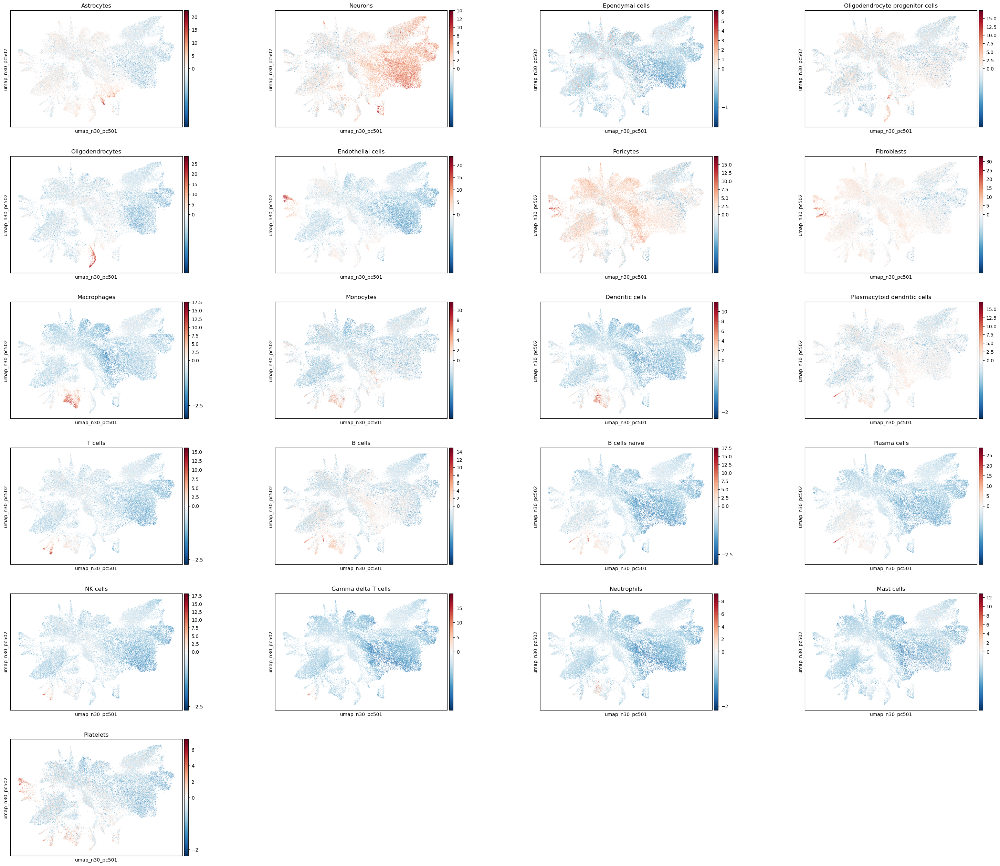

In [37]:
sc.pl.embedding(score_pang, basis="umap_n30_pc50", color=score_pang.obsm["score_ulm"].columns.tolist(), wspace=0.4, cmap="RdBu_r", vcenter=0)


In [39]:
df_pang = dc.tl.rankby_group(adata=score_pang, groupby="leiden_r1.2_n30_pc50", reference="rest", method="t-test_overestim_var")
df_pang = df_pang[df_pang["stat"] > 0]

In [40]:
df_pang["group"].unique()

['3', '7', '19', '20', '14', ..., '4', '24', '6', '17', '22']
Length: 27
Categories (27, object): ['0', '1', '10', '11', ..., '6', '7', '8', '9']

In [41]:
n_ctypes = 3
ctypes_dict_pang = df_pang.groupby("group").head(n_ctypes).groupby("group")["name"].apply(lambda x: list(x)).to_dict()
ctypes_dict_pang

{'0': ['Neurons', 'Plasmacytoid dendritic cells'],
 '1': ['Gamma delta T cells', 'Neutrophils', 'Mast cells'],
 '10': ['Neurons', 'Mast cells', 'Oligodendrocyte progenitor cells'],
 '11': ['Astrocytes', 'Pericytes', 'Plasmacytoid dendritic cells'],
 '12': ['Gamma delta T cells', 'Neutrophils', 'Fibroblasts'],
 '13': ['Macrophages', 'B cells naive', 'Dendritic cells'],
 '14': ['Neurons', 'Pericytes', 'Plasmacytoid dendritic cells'],
 '15': ['Fibroblasts', 'Endothelial cells', 'Platelets'],
 '16': ['T cells', 'B cells naive', 'NK cells'],
 '17': ['Neurons', 'Mast cells', 'Gamma delta T cells'],
 '18': ['Oligodendrocytes', 'Oligodendrocyte progenitor cells', 'Astrocytes'],
 '19': ['Neurons', 'Platelets', 'Gamma delta T cells'],
 '2': ['Pericytes', 'Fibroblasts', 'Endothelial cells'],
 '20': ['Endothelial cells', 'Platelets', 'Fibroblasts'],
 '21': ['Fibroblasts', 'Endothelial cells', 'Pericytes'],
 '22': ['Plasma cells', 'Plasmacytoid dendritic cells', 'B cells naive'],
 '23': ['Oligodend

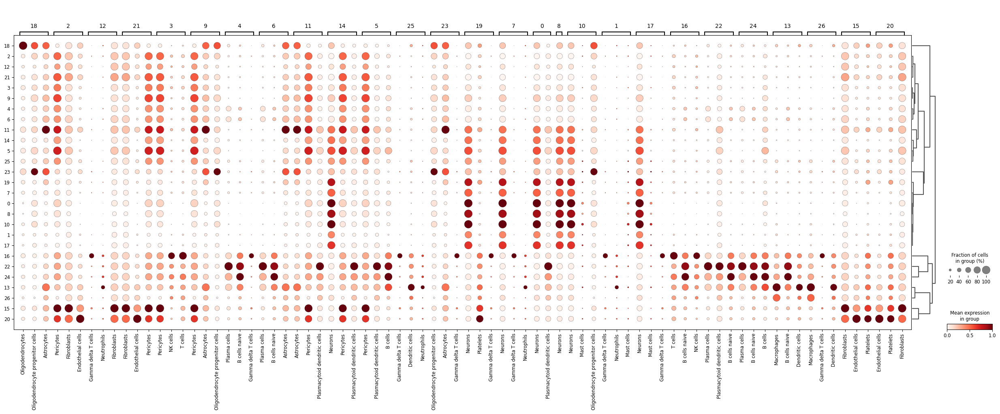

In [43]:
sc.tl.dendrogram(score_pang, groupby="leiden_r1.2_n30_pc50")
sc.pl.dotplot(score_pang, ctypes_dict_pang, groupby="leiden_r1.2_n30_pc50", standard_scale="var", dendrogram=True)

In [44]:
matches = markers.where(markers.isin(etmr1.var.index))

# first non-null (first match)
markers["target"] = matches.bfill(axis=1).iloc[:, 0]

result = markers[markers["target"].notna()][["source", "target"]]
result

,source,target
10,Dendritic,AR
28,Schwann,CDH19
102,Malignant,C1orf61
103,Schwann,CHM
130,Dendritic,RAD1
145,Bcell,BRD8
156,RG,TMSB15A
168,Oligodendrocytes,C10orf90
169,Bcell,CD37
170,Astrocytes,CDH20


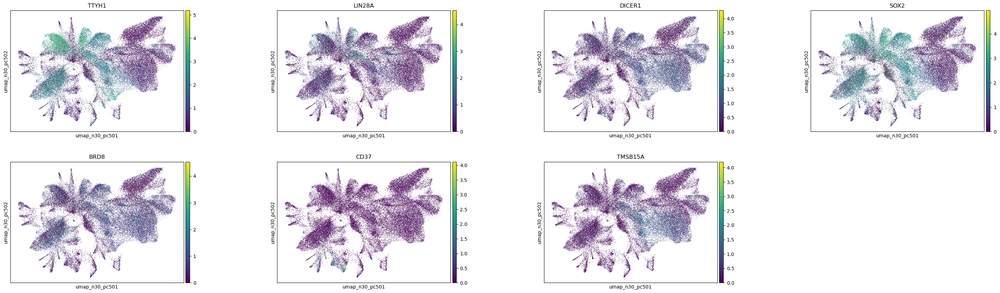

In [45]:
sc.pl.embedding(etmr1, basis="umap_n30_pc50", color=["TTYH1", "LIN28A", "DICER1", "SOX2", "BRD8", "CD37", "TMSB15A"], wspace=0.4)

In [46]:
dc.mt.ulm(data=etmr1, net=result, tmin=3)
score_manual = dc.pp.get_obsm(adata=etmr1, key="score_ulm")
score_manual.obsm["score_ulm"]

,Malignant,Oligodendrocytes,Schwann
AAACAAGCATTCGGTTACTACTCA-1-GSM8058157_KK22-H-225,1.513435,0.657944,-0.495355
AAACCAGGTTGCATCGACTACTCA-1-GSM8058157_KK22-H-225,-0.538635,0.534794,1.262577
AAACGGGCAATAACCGACTACTCA-1-GSM8058157_KK22-H-225,-0.399439,-1.153820,-0.399439
AAACTGGGTGCACAAAACTACTCA-1-GSM8058157_KK22-H-225,-0.619269,2.341808,-0.619269
AAAGATGCAATCGTGAACTACTCA-1-GSM8058157_KK22-H-225,-0.358088,2.864286,-0.358088
...,...,...,...
TTTGGACGTGGGTGTGAGTAGGCT-1-GSM8058164_KK23-H-511,-0.569618,-1.041527,-0.569618
TTTGGCGGTAAGGCCGAGTAGGCT-1-GSM8058164_KK23-H-511,3.922152,1.303087,-0.564950
TTTGGCGGTATAGCGAAGTAGGCT-1-GSM8058164_KK23-H-511,-0.551236,1.541376,-0.551236
TTTGGCGGTCAGGATAAGTAGGCT-1-GSM8058164_KK23-H-511,-0.347812,-0.002496,-0.347812


In [47]:
score_manual.obsm["score_ulm"].max()

Malignant            14.051153
Oligodendrocytes     21.648621
Schwann               6.878593
dtype: float64

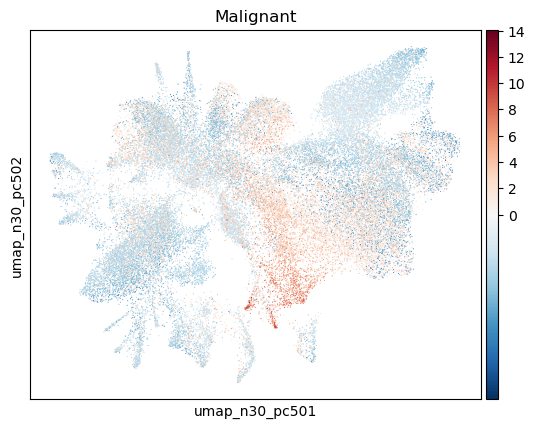

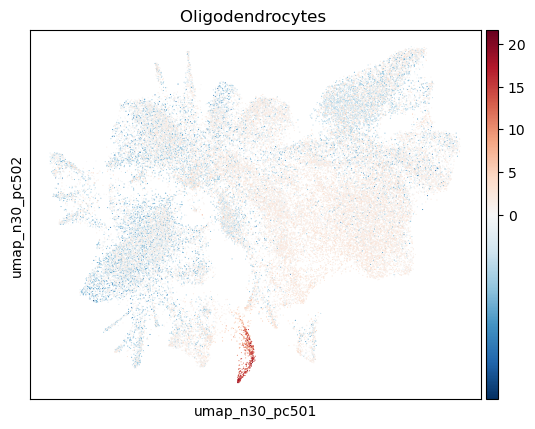

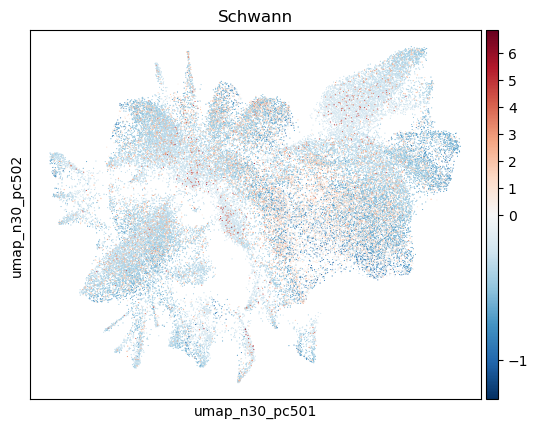

2025-12-19 12:00:58 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-12-19 12:00:58 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-12-19 12:00:58 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-12-19 12:00:59 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2025-12-19 12:00:59 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If 

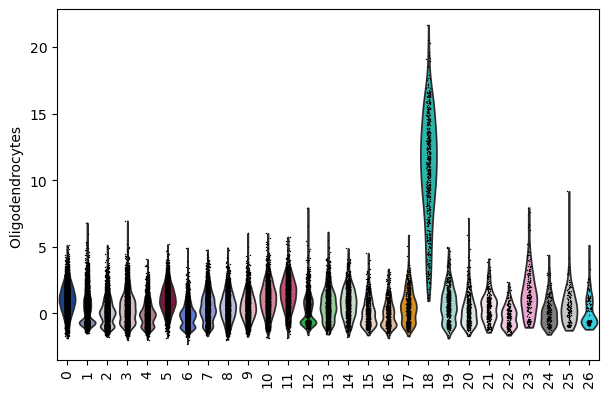

In [49]:
sc.pl.embedding(score_manual, basis="umap_n30_pc50", color=["Malignant"], wspace=0.4, cmap="RdBu_r", vcenter=0)
sc.pl.embedding(score_manual, basis="umap_n30_pc50", color=["Oligodendrocytes "], wspace=0.4, cmap="RdBu_r", vcenter=0)
sc.pl.embedding(score_manual, basis="umap_n30_pc50", color=["Schwann"], wspace=0.4, cmap="RdBu_r", vcenter=0)


sc.pl.violin(score_manual, keys=["Oligodendrocytes "],groupby="leiden_r1.2_n30_pc50", rotation=90)

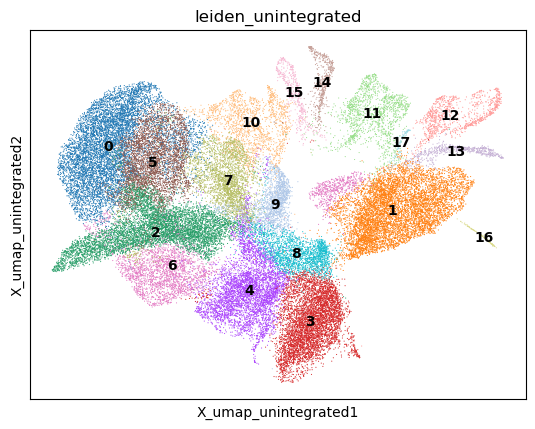

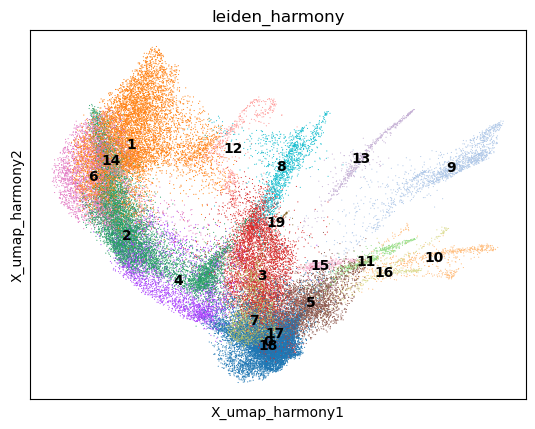

In [ ]:
sc.pl.embedding(etmr1, basis="X_umap_unintegrated", color=["leiden_unintegrated"], wspace=0.4,  vcenter=0, legend_loc='on data')


In [192]:
df = dc.tl.rankby_group(adata=score, groupby="leiden_unintegrated", reference="rest", method="t-test_overestim_var")
#df = df[df["stat"] > 0]


In [195]:
df


,group,reference,name,stat,meanchange,pval,padj
0,4,rest,Malignant,14.333761,0.492737,4.294749e-46,1.288425e-45
1,4,rest,Schwann,7.330277,0.140210,2.497587e-13,3.746381e-13
2,4,rest,Oligodendrocytes,-5.491296,-0.161517,4.119580e-08,4.119580e-08
3,3,rest,Oligodendrocytes,-20.949555,-0.565768,4.358608e-95,1.307582e-94
4,3,rest,Malignant,-7.539419,-0.226897,5.127502e-14,7.691253e-14
5,3,rest,Schwann,-2.150385,-0.035937,3.154742e-02,3.154742e-02
6,6,rest,Malignant,-14.826568,-0.574758,1.091536e-48,3.274609e-48
7,6,rest,Schwann,5.742994,0.138774,9.797381e-09,1.469607e-08
8,6,rest,Oligodendrocytes,-2.109505,-0.080133,3.495124e-02,3.495124e-02
9,5,rest,Malignant,-10.901978,-0.374074,1.897278e-27,5.691834e-27


In [197]:
n_ctypes = 3
ctypes_dict = df.groupby("group").head(n_ctypes).groupby("group")["name"].apply(lambda x: list(x)).to_dict()
ctypes_dict

{'0': ['Oligodendrocytes ', 'Malignant', 'Schwann'],
 '1': ['Oligodendrocytes ', 'Malignant', 'Schwann'],
 '10': ['Malignant', 'Oligodendrocytes ', 'Schwann'],
 '11': ['Malignant', 'Schwann', 'Oligodendrocytes '],
 '12': ['Malignant', 'Oligodendrocytes ', 'Schwann'],
 '13': ['Malignant', 'Oligodendrocytes ', 'Schwann'],
 '14': ['Oligodendrocytes ', 'Malignant', 'Schwann'],
 '15': ['Schwann', 'Malignant', 'Oligodendrocytes '],
 '16': ['Oligodendrocytes ', 'Malignant', 'Schwann'],
 '17': ['Oligodendrocytes ', 'Malignant', 'Schwann'],
 '2': ['Malignant', 'Oligodendrocytes ', 'Schwann'],
 '3': ['Oligodendrocytes ', 'Malignant', 'Schwann'],
 '4': ['Malignant', 'Schwann', 'Oligodendrocytes '],
 '5': ['Malignant', 'Schwann', 'Oligodendrocytes '],
 '6': ['Malignant', 'Schwann', 'Oligodendrocytes '],
 '7': ['Malignant', 'Oligodendrocytes ', 'Schwann'],
 '8': ['Schwann', 'Oligodendrocytes ', 'Malignant'],
 '9': ['Oligodendrocytes ', 'Malignant', 'Schwann']}

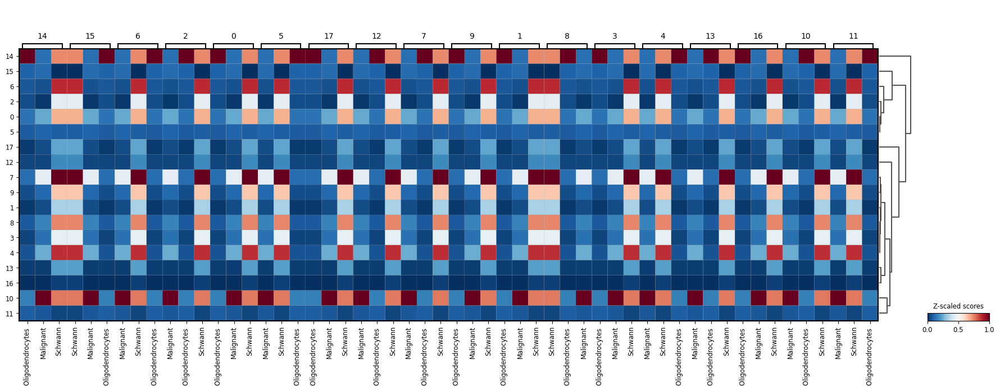

In [198]:
sc.pl.matrixplot(
    adata=score,
    var_names=ctypes_dict,
    groupby="leiden_unintegrated",
    dendrogram=True,
    standard_scale="var",
    colorbar_title="Z-scaled scores",
    cmap="RdBu_r",
    categories_order=ctypes_dict.keys()
)


In [150]:
etmr_mark = pd.read_excel("/home/sofia/Projects/etmr/defaria/marker_ref.xlsx", sheet_name="etmr_sig")
etmr_mark

,source,target
0,up,ABCB5
1,up,ACRV1
2,up,ACVR2A
3,up,ACVR2B
4,up,ADAM7
...,...,...
304,Down,WBP2NL
305,Down,WFDC3
306,Down,ZHX1
307,Down,ZNF487


In [151]:
dc.mt.ulm(data=etmr1, net=etmr_mark, tmin=3)
score_sig = dc.pp.get_obsm(adata=etmr1, key="score_ulm")
score_sig.obsm["score_ulm"]

,Down,up
AAACAAGCATTCGGTTACTACTCA-1-GSM8058157_KK22-H-225,-1.943492,4.087812
ATTGTTGGTCACGATTACTACTCA-1-GSM8058157_KK22-H-225,-2.676520,3.495886
ATTCGATTCTTGAAGAACTACTCA-1-GSM8058157_KK22-H-225,-1.549111,3.892494
ATTCACCCAAGCTTTCACTACTCA-1-GSM8058157_KK22-H-225,-1.057731,5.626077
ATGGGTTAGATATTGGACTACTCA-1-GSM8058157_KK22-H-225,-2.576160,5.269790
...,...,...
AATGCGCCAGCTCGCTACTTTAGG-1-GSM8058159_KK22-H-227,-1.707847,4.416385
AATGCGCCAGCCATAAACTTTAGG-1-GSM8058159_KK22-H-227,-2.232022,2.310525
AATGGATGTGGGAACTACTTTAGG-1-GSM8058159_KK22-H-227,-3.404126,3.729399
ACAAAGGAGCCACTCGACTTTAGG-1-GSM8058159_KK22-H-227,-3.517456,3.739713


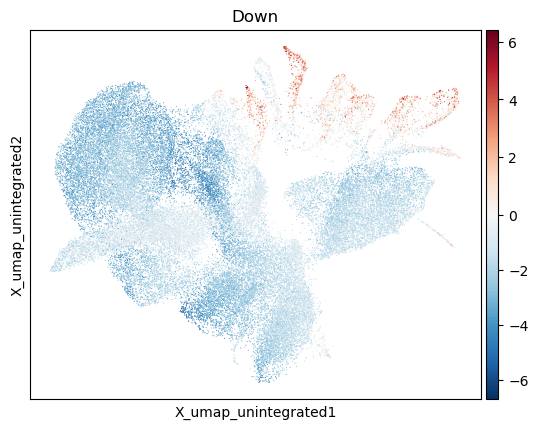

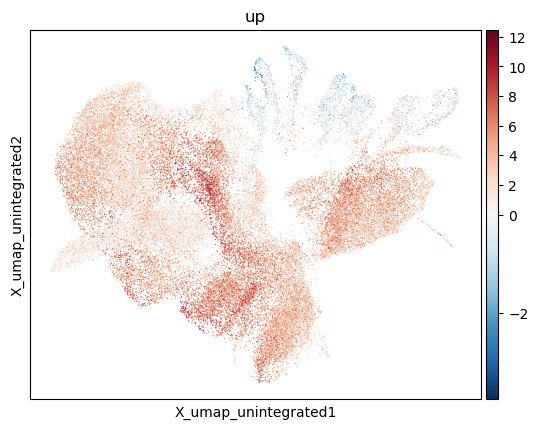

In [ ]:
sc.pl.embedding(score_sig, basis="X_umap_unintegrated", color=["Down"], wspace=0.4, cmap="RdBu_r", vcenter=0)
sc.pl.embedding(score_sig, basis="X_umap_unintegrated", color=["up"], wspace=0.4, cmap="RdBu_r", vcenter=0)


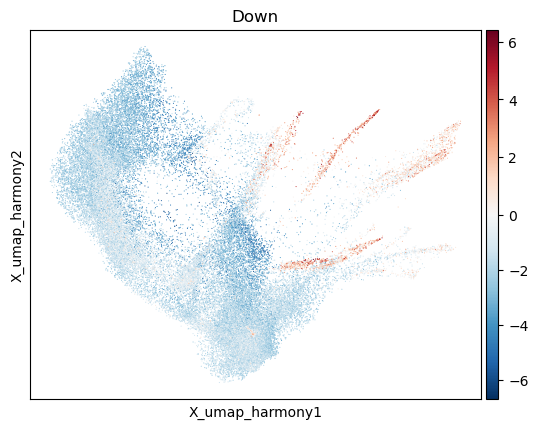

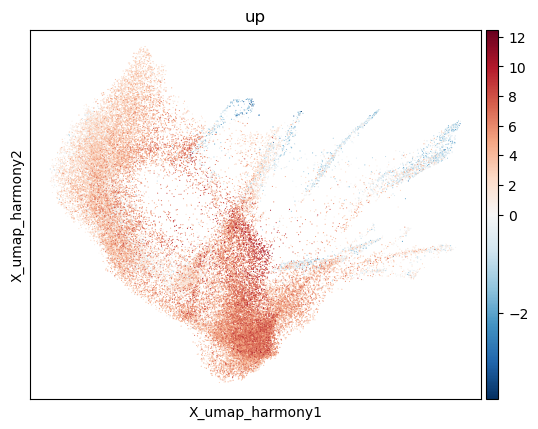

In [185]:
sc.pl.embedding(score_sig, basis="X_umap_harmony", color=["Down"], wspace=0.4, cmap="RdBu_r", vcenter=0)
sc.pl.embedding(score_sig, basis="X_umap_harmony", color=["up"], wspace=0.4, cmap="RdBu_r", vcenter=0)


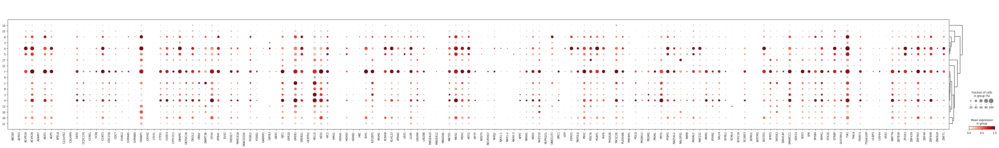

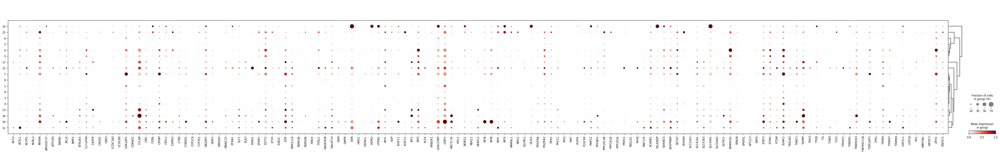

In [184]:
etmr_mark = etmr_mark[etmr_mark["target"].isin(etmr1.var_names)]
sc.pl.dotplot(etmr1, etmr_mark[etmr_mark["source"]=="up"]["target"], "leiden_unintegrated", dendrogram=True, standard_scale="var")
sc.pl.dotplot(etmr1, etmr_mark[etmr_mark["source"]=="Down"]["target"], "leiden_unintegrated", dendrogram=True, standard_scale="var")

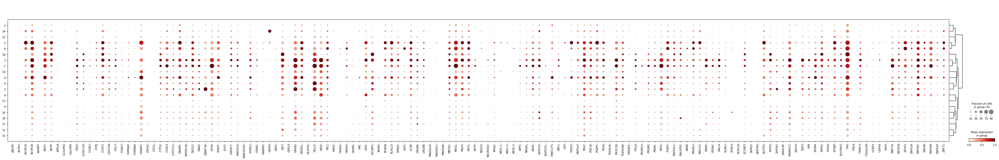

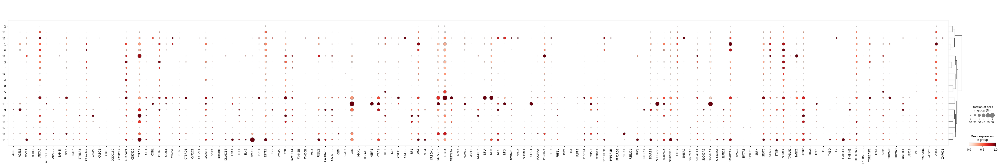

In [187]:
sc.tl.dendrogram(etmr1, groupby="leiden_harmony")

sc.pl.dotplot(etmr1, etmr_mark[etmr_mark["source"]=="up"]["target"], "leiden_harmony", dendrogram=True, standard_scale="var")
sc.pl.dotplot(etmr1, etmr_mark[etmr_mark["source"]=="Down"]["target"], "leiden_harmony", dendrogram=True, standard_scale="var")

In [ ]:
# Use pseudobulk to get markers per cluster instead of per cell
sc.get.rank_genes_groups_df(etmr1, group=None) 
sc.pl.rank_genes_groups(etmr1, n_genes=20)

In [ ]:
etmr1.uns["rank_genes_groups_unintegrated"] = etmr1.uns["rank_genes_groups"]
sc.tl.rank_genes_groups(etmr1, groupby="leiden_harmony", method="wilcoxon")
sc.tl.dendrogram(etmr1, groupby="leiden_harmony")
sc.pl.rank_genes_groups_dotplot(etmr1, groupby="leiden_harmony", standard_scale="var", n_genes=5)

In [ ]:
etmr1.uns["rank_genes_groups_harmony"] = etmr1.uns["rank_genes_groups"]
sc.tl.rank_genes_groups(etmr1, groupby="leiden_scanorama", method="wilcoxon")
sc.tl.dendrogram(etmr1, groupby="leiden_scanorama")
sc.pl.rank_genes_groups_dotplot(etmr1, groupby="leiden_scanorama", standard_scale="var", n_genes=5)
etmr1.uns["rank_genes_groups_scanorama"] = etmr1.uns["rank_genes_groups"]

In [ ]:
etmr1

In [ ]:
etmr1.write_h5ad("/home/sofia/Projects/etmr/defaria/snRNA/data/processed/snrna_data_mark.h5ad")

In [ ]:
etmr1.uns

In [ ]:
def scanpy_rank_genes_to_df(adata, groupby="leiden_unintegrated", rank_key="rank_genes_groups_unintegrated"):
    r = adata.uns[rank_key]
    groups = r["names"].dtype.names
    
    rows = []
    for g in groups:
        df = pd.DataFrame({
            "cluster": g,
            "gene": r["names"][g],
            "logfc": r["logfoldchanges"][g],
            "pvals_adj": r["pvals_adj"][g],
            "scores": r["scores"][g]
        })
        rows.append(df)
    return pd.concat(rows)



markers_df = scanpy_rank_genes_to_df(etmr1)
markers_df.to_csv("/home/sofia/Projects/etmr/defaria/snRNA/tables/scanpy_markers_unintegrated.csv", index=False)
markers_df_harmony = scanpy_rank_genes_to_df(etmr1, groupby="leiden_harmony", rank_key="rank_genes_groups_harmony")
markers_df_harmony.to_csv("/home/sofia/Projects/etmr/defaria/snRNA/tables/scanpy_markers_harmony.csv", index=False)
markers_df_scanorama = scanpy_rank_genes_to_df(etmr1, groupby="leiden_scanorama", rank_key="rank_genes_groups_scanorama")
markers_df_scanorama.to_csv("/home/sofia/Projects/etmr/defaria/snRNA/tables/scanpy_markers_scanorama.csv", index=False)

In [ ]:
markers_df_scanorama

In [ ]:
pd.DataFrame(etmr1.uns["rank_genes_groups"]["names"])


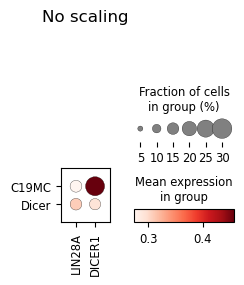

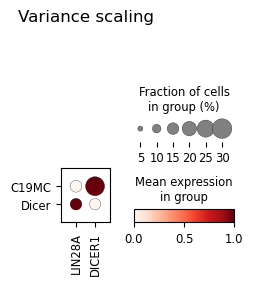

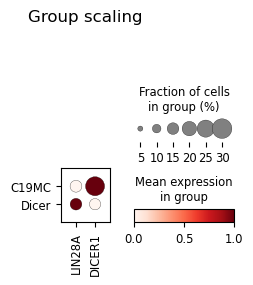

In [11]:

sc.pl.dotplot(etmr1, [ "LIN28A", "DICER1", ], groupby="Tumor_Type", standard_scale=None, title="No scaling")
sc.pl.dotplot(etmr1, ["LIN28A", "DICER1",], groupby="Tumor_Type", standard_scale="var", title="Variance scaling")
sc.pl.dotplot(etmr1, [ "LIN28A", "DICER1"], groupby="Tumor_Type", standard_scale="group", title="Group scaling")
